# Signal-level daily LS report

The result cache contains the Cartesian product of `FREQUENCIES`, `WEIGHT_METHODS`, `BREAKPOINTS`, and `SIC_LEVELS`. Choose singular values below for the one-configuration table and curve; leave the plural lists as lists to overlay configurations in the 11-panel figure. Curves show cumulative simple return from 0%.

In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd().resolve()
while not (PROJECT / 'data' / 'derived').exists() and PROJECT != PROJECT.parent:
    PROJECT = PROJECT.parent
ROOT = PROJECT / 'data' / 'derived'
RESULTS = ROOT / 'backtest'
CONFIG = PROJECT / 'configs' / 'base.yaml'

# Each plural name is a list used by the Cartesian-product report.
FREQUENCIES = ['daily', 'monthly']
WEIGHT_METHODS = ['rank', 'quintile']
BREAKPOINTS = [0.25, 0.75]
SIC_LEVELS = [None, 1]

# Singular aliases select one configuration for the inspection cells.
FREQUENCY = FREQUENCIES[0]
WEIGHT_METHOD = WEIGHT_METHODS[0]
BREAKPOINT = BREAKPOINTS[-1]
SIC_LEVEL = SIC_LEVELS[1]
SIGNAL = 'Trough Coverage Clean Accrual Rollover'
EXECUTION = 'score at close t; execute at close t+1; realize close-to-close return at t+2'

# To rebuild from any notebook working directory:
# %run -m daily_signal_backtest.cli wide-grid --config {CONFIG}

In [25]:
if not (RESULTS / 'performance_metrics.csv').exists():
    raise FileNotFoundError(f'No completed backtest cache at {RESULTS}. Run the command in the setup cell first.')
metrics = pd.read_csv(RESULTS / 'performance_metrics.csv')
daily = pd.read_parquet(RESULTS / 'daily_ls_returns.parquet')
def select_sic(frame, level):
    return frame.sic_level.isna() if level is None else frame.sic_level.eq(level)

one_row = metrics.loc[
    metrics['rebalance_frequency'].eq(FREQUENCY)
    & metrics['weight_method'].eq(WEIGHT_METHOD)
    & metrics['microcap_percentile'].eq(BREAKPOINT)
    & select_sic(metrics, SIC_LEVEL)
    & metrics['signal'].eq(SIGNAL)
].copy()
one_row.insert(0, 'execution', EXECUTION)
display(one_row)
assert len(one_row) == 1

,execution,signal,microcap_percentile,sic_level,rebalance_frequency,weight_method,n_days,AnnRet,AnnVol,Sharpe,AvgDlyBets,2WayTurnover,MDD,t_stat
524,score at close t; execute at close t+1; realiz...,Trough Coverage Clean Accrual Rollover,0.75,1.0,daily,zscore,6538,0.010865,0.023132,0.478719,1024.538238,0.021993,-0.092188,2.516017


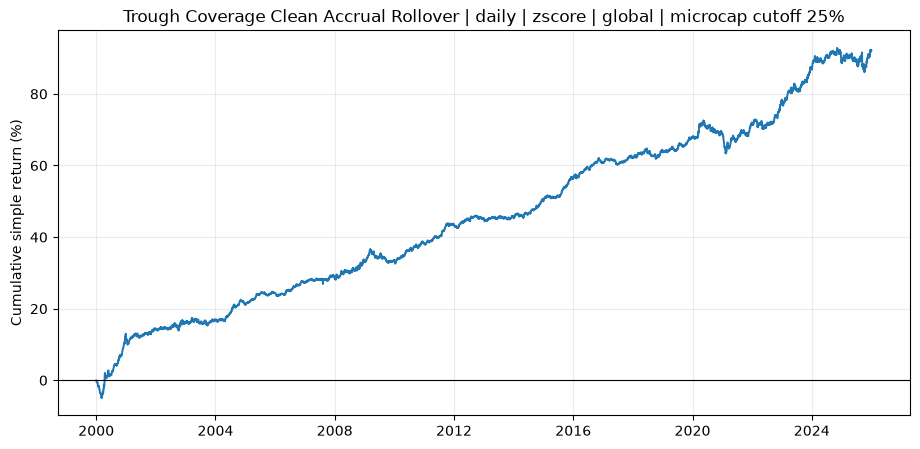

In [5]:
series = daily.loc[
    daily['rebalance_frequency'].eq(FREQUENCY)
    & daily['weight_method'].eq(WEIGHT_METHOD)
    & daily['microcap_percentile'].eq(BREAKPOINT)
    & select_sic(daily, SIC_LEVEL)
    & daily['signal'].eq(SIGNAL)
].sort_values('date')
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(series['date'], 100 * series['cum_return'], lw=1.4, color='#1f77b4')
ax.axhline(0, color='black', lw=0.8)
sic_label = 'global' if SIC_LEVEL is None else f'SIC level {SIC_LEVEL}'
ax.set(title=f'{SIGNAL} | {FREQUENCY} | {WEIGHT_METHOD} | {sic_label} | microcap cutoff {BREAKPOINT:.0%}', xlabel='', ylabel='Cumulative simple return (%)')
ax.grid(alpha=0.25)
plt.show()

In [21]:
# The strictest specification
FREQUENCIES = ['daily']
WEIGHT_METHODS = ['rank']
BREAKPOINTS = [0.75]
SIC_LEVELS = [1]

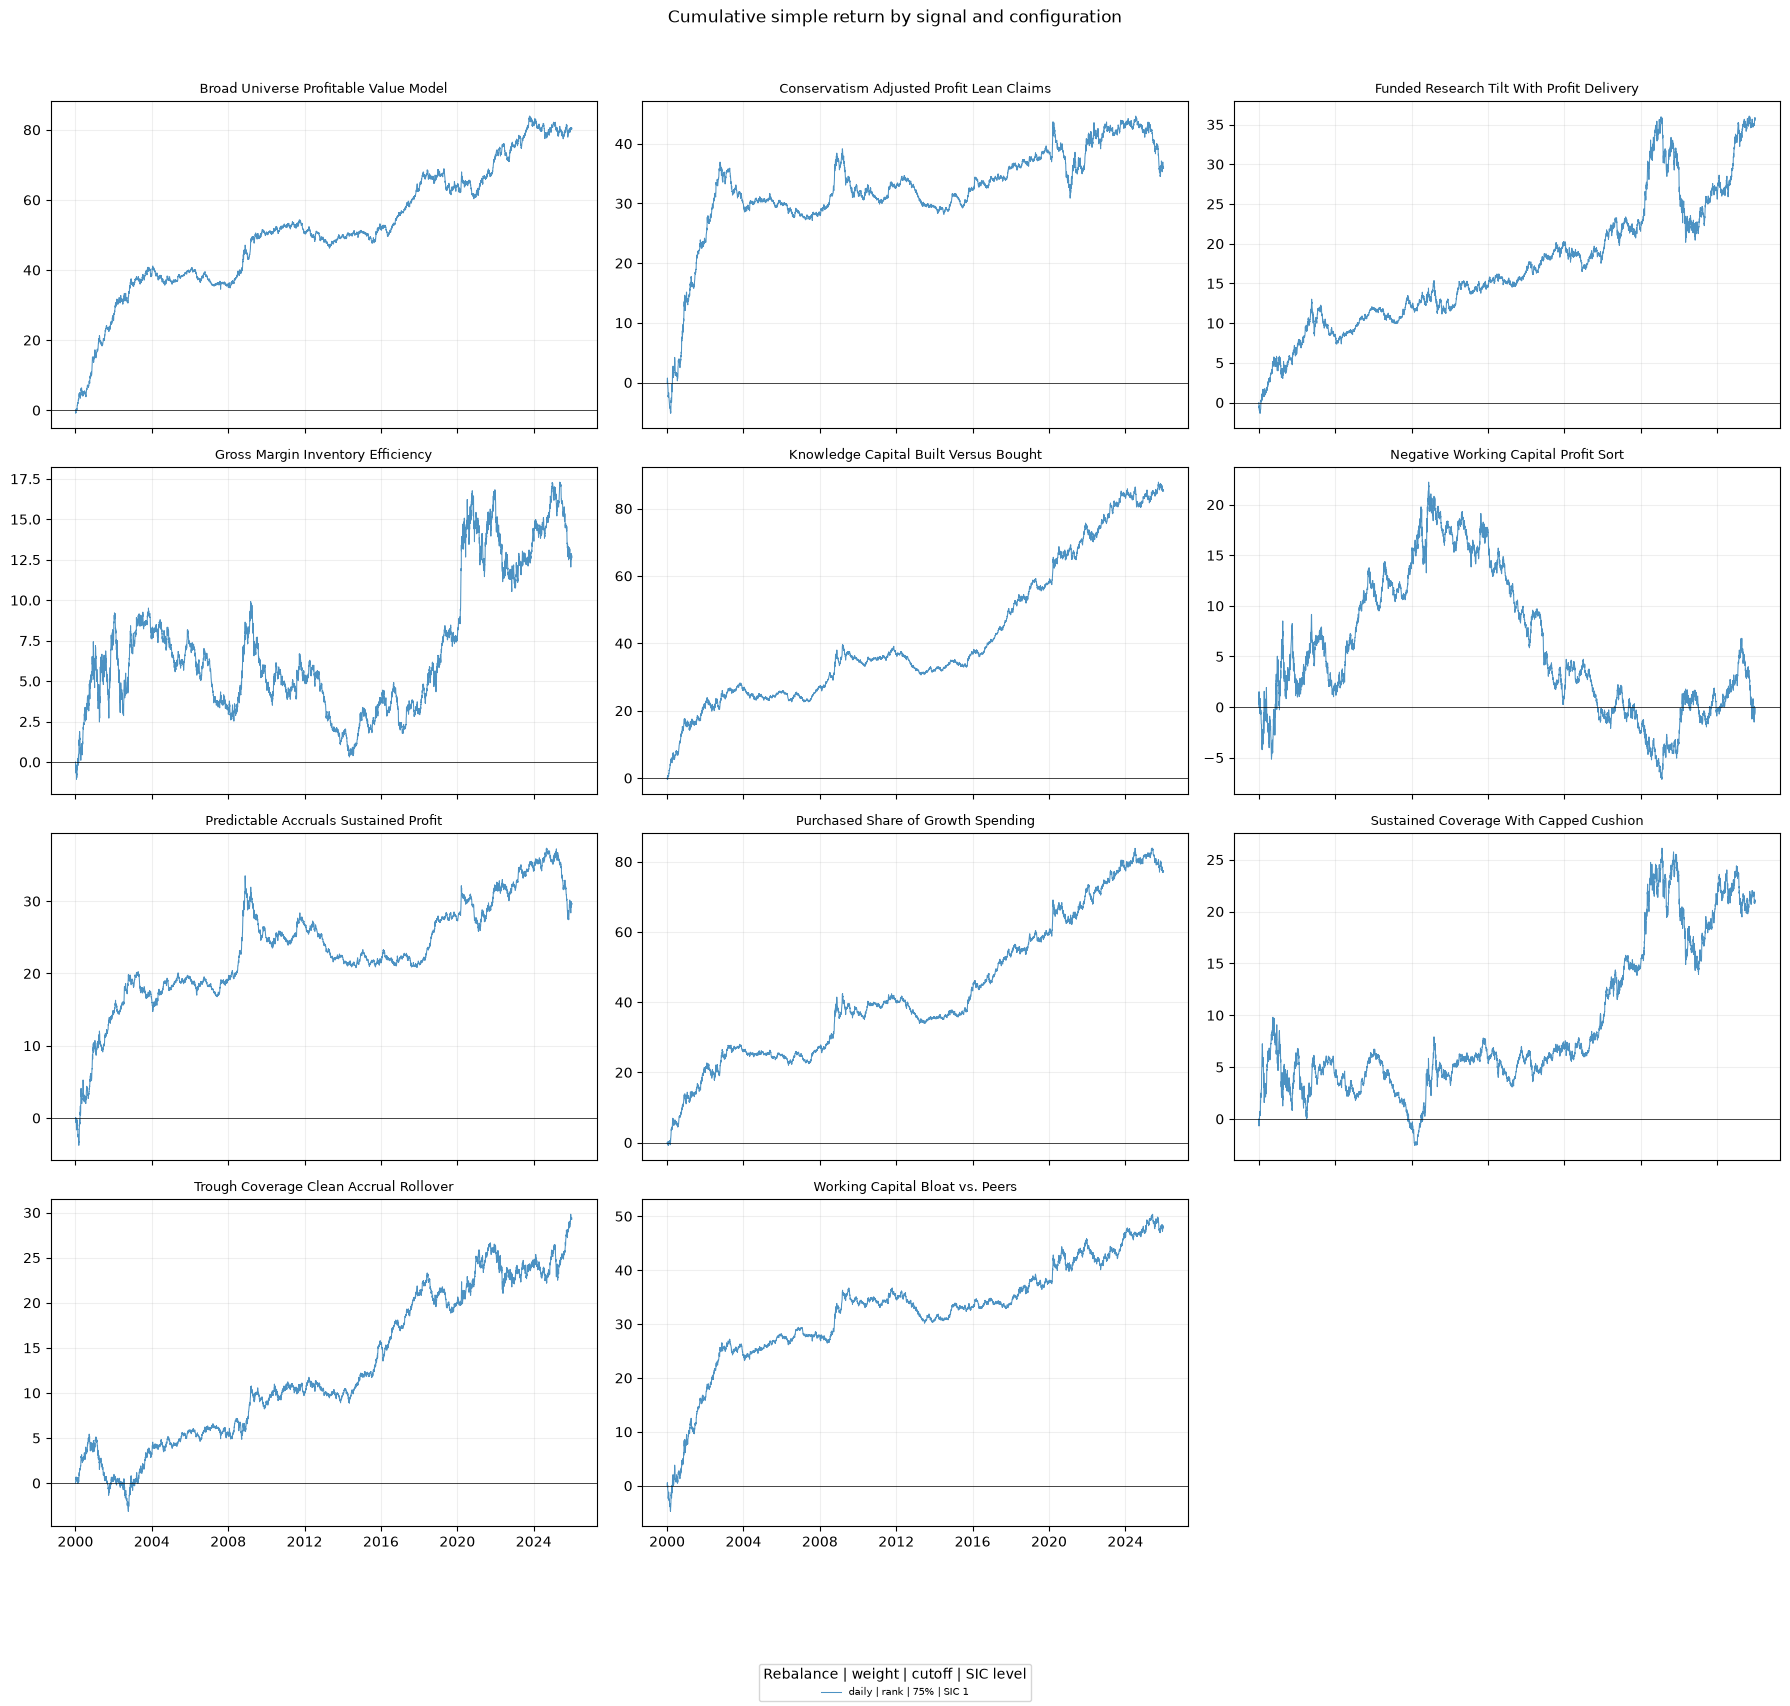

In [22]:
# 11 signal panels, with a curve for every selected Cartesian-product setting.
from itertools import product

series_by_config = {}
for frequency, method, breakpoint, sic_level in product(FREQUENCIES, WEIGHT_METHODS, BREAKPOINTS, SIC_LEVELS):
    mask = (daily.rebalance_frequency.eq(frequency) & daily.weight_method.eq(method)
            & daily.microcap_percentile.eq(breakpoint) & select_sic(daily, sic_level))
    subset = daily.loc[mask]
    if not subset.empty:
        series_by_config[(frequency, method, breakpoint, sic_level)] = subset
if not series_by_config:
    raise ValueError('The selected Cartesian-product configurations are absent from the result cache.')
signals = sorted({signal for frame in series_by_config.values() for signal in frame.signal.unique()})
fig, axes = plt.subplots(4, 3, figsize=(18, 17), sharex=True)
axes = axes.ravel()
for ax, signal in zip(axes, signals):
    for (frequency, method, breakpoint, sic_level), frame in series_by_config.items():
        curve = frame.loc[frame.signal.eq(signal)].sort_values('date')
        if not curve.empty:
            sic_label = 'global' if sic_level is None else f'SIC {sic_level}'
            ax.plot(curve.date, 100 * curve.cum_return, lw=.75, alpha=.8,
                    label=f'{frequency} | {method} | {breakpoint:.0%} | {sic_label}')
    ax.axhline(0, color='black', lw=.5)
    ax.set_title(signal, fontsize=9)
    ax.grid(alpha=.2)
for ax in axes[len(signals):]:
    ax.set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Rebalance | weight | cutoff | SIC level', loc='lower center', ncol=3, fontsize=7)
fig.suptitle('Cumulative simple return by signal and configuration', y=.995)
fig.tight_layout(rect=(0, .08, 1, .98))
plt.show()

In [ ]:
# Other different specifications
FREQUENCIES = ['daily', 'monthly']
WEIGHT_METHODS = ['rank', 'quintile']
BREAKPOINTS = [0.25, 0.75]
SIC_LEVELS = [None, 1]

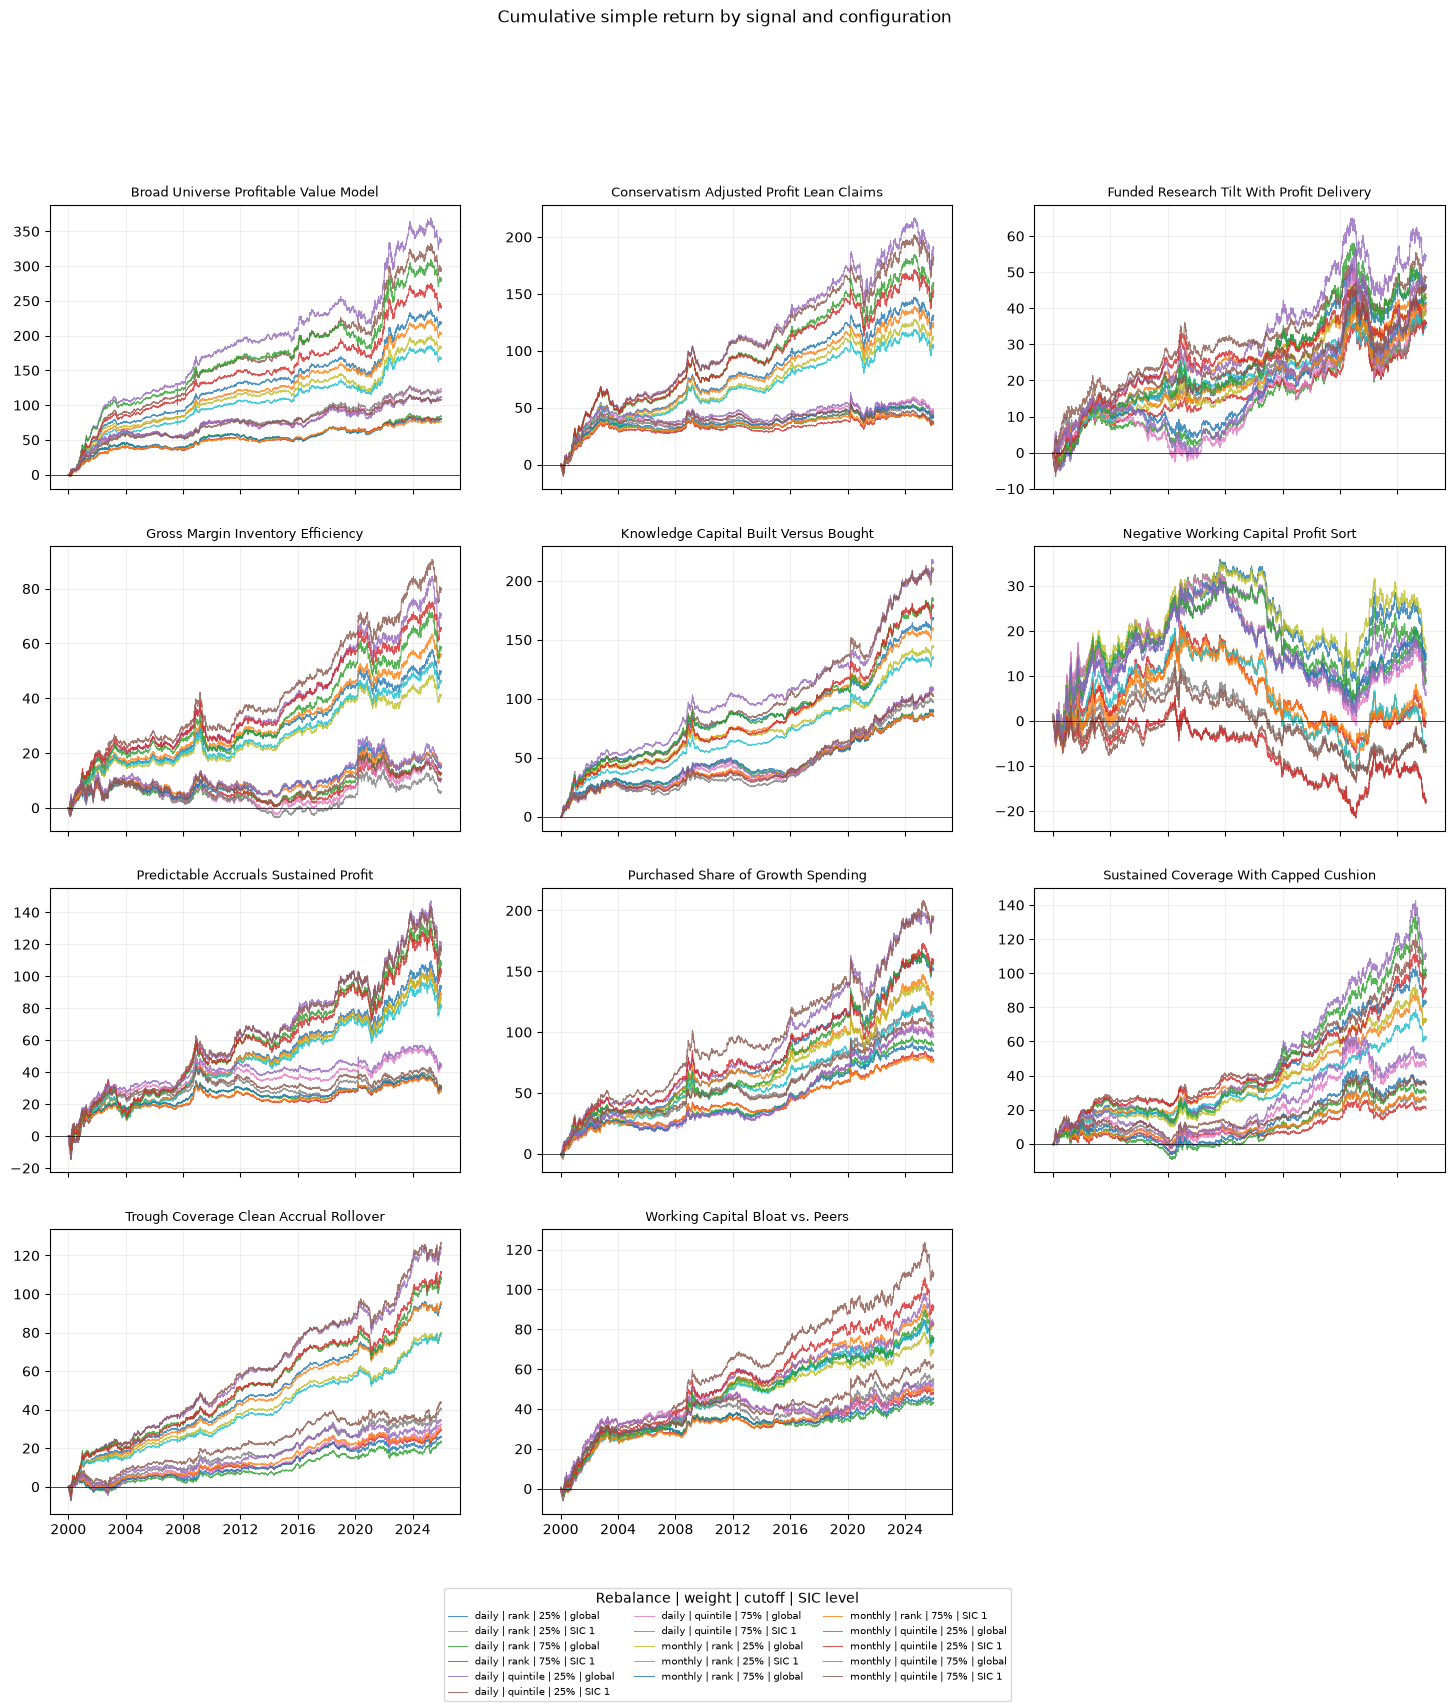

In [32]:
# 11 signal panels, with a curve for every selected Cartesian-product setting.
from itertools import product

series_by_config = {}
for frequency, method, breakpoint, sic_level in product(FREQUENCIES, WEIGHT_METHODS, BREAKPOINTS, SIC_LEVELS):
    mask = (daily.rebalance_frequency.eq(frequency) & daily.weight_method.eq(method)
            & daily.microcap_percentile.eq(breakpoint) & select_sic(daily, sic_level))
    subset = daily.loc[mask]
    if not subset.empty:
        series_by_config[(frequency, method, breakpoint, sic_level)] = subset
if not series_by_config:
    raise ValueError('The selected Cartesian-product configurations are absent from the result cache.')
signals = sorted({signal for frame in series_by_config.values() for signal in frame.signal.unique()})
fig, axes = plt.subplots(4, 3, figsize=(18, 17), sharex=True)
axes = axes.ravel()
for ax, signal in zip(axes, signals):
    for (frequency, method, breakpoint, sic_level), frame in series_by_config.items():
        curve = frame.loc[frame.signal.eq(signal)].sort_values('date')
        if not curve.empty:
            sic_label = 'global' if sic_level is None else f'SIC {sic_level}'
            ax.plot(curve.date, 100 * curve.cum_return, lw=.75, alpha=.8,
                    label=f'{frequency} | {method} | {breakpoint:.0%} | {sic_label}')
    ax.axhline(0, color='black', lw=.5)
    ax.set_title(signal, fontsize=9)
    ax.grid(alpha=.2)
for ax in axes[len(signals):]:
    ax.set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Rebalance | weight | cutoff | SIC level', loc='lower center', ncol=3, fontsize=7)
fig.suptitle('Cumulative simple return by signal and configuration', y=.995)

plt.show()